# 03 – Platzmasse: Wie viel Fläche braucht ein Parkplatz?

**Ziel.** Für die Zählung brauchen wir die Fläche **eines** Parkplatzes. Das Netz liefert am Schluss keine Anzahl, sondern Fläche; daraus wird gezählt: Anzahl = Fläche ÷ Platzfläche.

**Warum.** Ist die Platzfläche falsch, ist die Zählung falsch, auch wenn die Fläche perfekt erkannt wird. Darum kommt sie aus zwei belegten Quellen (`01b`, Abschnitt 1 und Abschnitt 11, E1 und E5):

| Mass | Quelle |
| --- | --- |
| **Tiefe** des Feldes quer zur Reihe | Norm: 1,90 m für Längsfelder, 5,00 m für Quer- und Schrägfelder |
| **Abstand** von Feld zu Feld entlang der Reihe | eigene Ground Truth, gemessen in den **Lernblöcken** |

**Eingaben:** `daten/ground_truth/ground_truth_hand.json`, `daten/verarbeitet/aufteilung.csv` (Notebook 02).
**Ausgaben:** `daten/verarbeitet/platzmasse.json`, `daten/verarbeitet/ringe.csv` (je Ring: Reihe, Abstand, Klasse), Abbildung `03_abstaende.png`.

In [1]:
import json                        # Einstellungen, Ground Truth und Platzmasse lesen und schreiben
from pathlib import Path           # Pfade zusammensetzen

ROOT = Path.cwd().parent                             # Projektordner (eine Ebene über notebooks/)
VERARB = ROOT / "daten" / "verarbeitet"              # abgeleitete Daten
ABB = ROOT / "ergebnisse" / "abbildungen"            # Abbildungen
HAND = ROOT / "daten" / "ground_truth" / "ground_truth_hand.json"   # Ground Truth des Auftraggebers (wird nur gelesen)

import numpy as np                 # Rechnen
import pandas as pd                # Tabellen
import matplotlib.pyplot as plt    # Abbildungen
from scipy.spatial import cKDTree  # findet zu jedem Punkt schnell den nächsten Nachbarn

**Einstellungen dieses Schritts.**

| Einstellung | Wert | Woher |
| --- | --- | --- |
| `ENG_M` | 4 m | Grenze zwischen "eng" und "weit". In `ground_truth_pruefen`, Abschnitt 5, an den DAV-Punkten abgelesen: Quer- und Schrägfelder stehen 2 bis 3,6 m auseinander, Längsfelder 4,3 bis 9,5 m |
| `EINZELN_M` | 9 m | ohne Ring innerhalb von 9 m steht ein Feld einzeln |
| `LINIE_M` | 1 m | so weit darf ein Ring neben einer Linie liegen, um noch zur Reihe zu zählen (weniger als eine halbe Feldbreite) |
| `SUCHRADIUS_M` | 13 m | Umkreis, in dem die Ringe einer Reihe gesucht werden (gut zwei Längsfelder) |
| `TIEFE_WEIT_M` | 1,90 m | Norm für Längsfelder (`01b`, Abschnitt 1) |
| `TIEFE_ENG_M` | 5,00 m | Norm für Querfelder; Schrägfelder liegen mit 4,80 bis 5,25 m höchstens 5 % daneben |

In [2]:
ENG_M = 4.0
EINZELN_M = 9.0
LINIE_M = 1.0
SUCHRADIUS_M = 13.0
TIEFE_WEIT_M = 1.90
TIEFE_ENG_M = 5.00

## 1. Die Reihe zu jedem Ring finden

**Worum es geht.** Im Werkzeug hat der Auftraggeber in die Mitte jedes Feldes einen Ring gesetzt. Stehen Autos **nebeneinander** (quer oder schräg), liegen die Ringe einer Reihe eng beisammen; stehen sie **hintereinander** (längs), liegen sie weit auseinander. Die im Werkzeug gespeicherte Parkart verwenden wir nicht: Sie ist oft vertauscht (`01b`, 10.2).

**Schritt 1: Felder lesen und ihre Gruppe nachschlagen.**

Vorher: Datei der Ground Truth → nachher: Tabelle der gesetzten Felder mit Ausschnitt und Gruppe.

In [3]:
erfasst = json.loads(HAND.read_text(encoding="utf-8"))             # einmal lesen; die Datei wird nicht verändert
KACHEL_M = erfasst["einstellungen"]["kachel_m"]                    # Seitenlänge eines Ausschnitts: 51,2 m
felder = pd.DataFrame(erfasst["felder"])
felder = felder[~felder.geloescht & ~felder.verborgen].reset_index(drop=True)   # gesetzte Felder, neu nummeriert
felder["kachel"] = "k_" + (felder.x // KACHEL_M).astype(int).astype(str) + "_" + (felder.y // KACHEL_M).astype(int).astype(str)

aufteilung = pd.read_csv(VERARB / "aufteilung.csv")                # Gruppe je Ausschnitt (Notebook 02)
felder["gruppe"] = felder.kachel.map(aufteilung.set_index("kachel").gruppe)
print(f"Gesetzte Felder: {len(felder)}")
print(felder.gruppe.value_counts(dropna=False).to_string())

Gesetzte Felder: 3278
gruppe
lernen        2000
testen         846
validieren     423
NaN              9


**Schritt 2: Warum nicht einfach der nächste Ring?** Der nächste Ring gehört nicht immer zur selben Reihe. Liegen zwei Reihen dicht nebeneinander, kann ein Ring der **anderen** Reihe näher sein als der Nachbar in der eigenen. Dann zeigte die Richtung quer zur Reihe.

Darum suchen wir zu jedem Ring die **Linie, auf der die meisten Ringe liegen**:
1. Jede Richtung zu einem Ring im Umkreis von 9 m ist ein Kandidat.
2. Für jeden Kandidaten zählen wir die Ringe im Umkreis von 13 m, die höchstens 1 m neben dieser Linie liegen.
3. Die Linie mit den meisten Ringen gewinnt. Bei Gleichstand gewinnt die mit dem näheren Ring.

Der **Abstand in der Reihe** ist dann der Abstand zum nächsten Ring auf dieser Linie.

`cKDTree` findet schnell alle Ringe im Umkreis. Wie weit ein Ring neben einer Linie liegt, ergibt das Kreuzprodukt aus seinem Versatz und der Richtung der Linie.

In [4]:
lage = felder[["x", "y"]].values                                   # x und y aller Ringe als Zahlenblock
baum = cKDTree(lage)                                               # Suchbaum über alle Ringe

def beste_linie(nummer):
    # Sucht für einen Ring die Linie mit den meisten Ringen. Ergebnis: (Abstand in der Reihe, Winkel, Ringe auf der Linie)
    umgebung = [n for n in baum.query_ball_point(lage[nummer], SUCHRADIUS_M) if n != nummer]   # Ringe im Umkreis, ohne den Ring selbst
    versatz = lage[umgebung] - lage[nummer]                        # Vektoren vom Ring zu den Ringen der Umgebung
    entfernung = np.hypot(versatz[:, 0], versatz[:, 1])            # ihre Entfernungen
    bestes = (0, np.inf, np.nan)                                   # (Ringe auf der Linie, Abstand, Winkel)
    for k in np.where(entfernung <= EINZELN_M)[0]:                 # jeder Ring bis 9 m gibt eine Richtung vor
        richtung = versatz[k] / entfernung[k]                      # Einheitsvektor dieser Richtung
        daneben = np.abs(versatz[:, 0] * richtung[1] - versatz[:, 1] * richtung[0])   # Abstand jedes Rings von der Linie
        auf_linie = daneben < LINIE_M
        kandidat = (int(auf_linie.sum()), entfernung[auf_linie].min(), np.arctan2(richtung[1], richtung[0]))
        if (kandidat[0], -kandidat[1]) > (bestes[0], -bestes[1]):   # mehr Ringe gewinnt; bei Gleichstand der nähere
            bestes = kandidat
    return bestes[1], bestes[2], bestes[0]

**Schritt 3: für alle Ringe, und ein Beispiel.** Die Liste `ergebnis` enthält für jeden Ring die Antwort der Funktion. Zum Vergleich steht daneben der Abstand zum nächsten Ring überhaupt. Wir zeigen einen Ring, bei dem die beiden Antworten verschieden sind.

Vorher: Ringe → nachher: je Ring der Abstand in der Reihe und die Richtung der Reihe.

In [5]:
naechster_m, _ = baum.query(lage, k=2)                             # Abstand zum nächsten Ring überhaupt (Spalte 1), zum Vergleich
ergebnis = [beste_linie(n) for n in range(len(felder))]            # für alle Ringe: (Abstand, Winkel, Ringe auf der Linie)
felder["abstand_m"] = [e[0] for e in ergebnis]                     # Abstand in der Reihe
felder["winkel"] = [e[1] for e in ergebnis]                        # Richtung der Reihe (Bogenmass)
felder["ringe_auf_linie"] = [e[2] for e in ergebnis]
felder["naechster_m"] = naechster_m[:, 1]

anders = felder[(felder.abstand_m - felder.naechster_m > 0.5) & np.isfinite(felder.abstand_m)]   # Reihe ist nicht der nächste Ring
beispiel = anders.iloc[0]
print(f"Beispiel-Ring bei ({beispiel.x:.1f}, {beispiel.y:.1f}):")
print(f"  nächster Ring überhaupt:    {beispiel.naechster_m:.2f} m entfernt")
print(f"  nächster Ring in der Reihe: {beispiel.abstand_m:.2f} m entfernt, auf einer Linie mit {beispiel.ringe_auf_linie} Ringen")
print(f"Bei {len(anders)} von {len(felder)} Ringen liegt der nächste Ring nicht in der eigenen Reihe.")

Beispiel-Ring bei (2682872.7, 1247162.9):
  nächster Ring überhaupt:    5.39 m entfernt
  nächster Ring in der Reihe: 5.94 m entfernt, auf einer Linie mit 4 Ringen
Bei 118 von 3278 Ringen liegt der nächste Ring nicht in der eigenen Reihe.


**Schritt 4: die Klasse.** `np.select` prüft die Bedingungen der Reihe nach: Abstand in der Reihe unter 4 m → `eng`; bis 9 m → `weit`; kein Ring innerhalb von 9 m → `einzeln`.

Vorher: Ringe mit Abstand in der Reihe → nachher: je Ring die Klasse.

In [6]:
felder["klasse"] = np.select([felder.abstand_m < ENG_M, felder.abstand_m <= EINZELN_M], ["eng", "weit"], default="einzeln")
felder[["id", "kachel", "gruppe", "x", "y", "abstand_m", "winkel", "klasse"]].to_csv(VERARB / "ringe.csv", index=False)   # für Notebook 04
print("Ringe je Klasse und Gruppe:")
pd.crosstab(felder.klasse, felder.gruppe, margins=True, margins_name="alle")

Ringe je Klasse und Gruppe:


gruppe,lernen,testen,validieren,alle
klasse,,,,
einzeln,63,15,18,96
eng,1032,484,227,1743
weit,905,347,178,1430
alle,2000,846,423,3269


**Schritt 5: Kontrolle an der DAV.** Bei den Feldern, die aus der DAV übernommen wurden, kennen wir die amtliche Parkart (`LPU` längs, `QPU` quer, `SCHPU` schräg). Sie dient hier nur als Kontrolle der Regel, nicht als Lösung. Stimmt die Regel, stehen `LPU` unter `weit` und `QPU`, `SCHPU` unter `eng`.

In [7]:
aus_dav = felder[felder.herkunft == "DAV"]
parkart_dav = pd.Series([vorschlag["parkart"] for vorschlag in aus_dav.vorschlag], index=aus_dav.index, name="Parkart der DAV")
kreuz = pd.crosstab(parkart_dav, aus_dav.klasse)
display(kreuz)
richtig = kreuz.loc["LPU", "weit"] + kreuz.loc["QPU", "eng"] + kreuz.loc["SCHPU", "eng"]
mit_reihe = kreuz[["eng", "weit"]].values.sum()
print(f"Regel und DAV stimmen überein bei {richtig} von {mit_reihe} Feldern mit Reihe ({100 * richtig / mit_reihe:.1f} %)")

klasse,einzeln,eng,weit
Parkart der DAV,,,
LPU,37,30,544
QPU,0,186,5
SCHPU,0,225,2


Regel und DAV stimmen überein bei 955 von 992 Feldern mit Reihe (96.3 %)


## 2. Der typische Abstand je Klasse

**Schritt 1: nur Lernblöcke, nur gewöhnliche Felder.** Gemessen wird in den Lernblöcken, damit die Testblöcke unberührt bleiben. Streifen (`═`) lassen wir weg: Dort hat der Auftraggeber die Ringe nach Schätzung gesetzt, nicht nach aufgemalten Feldern.

Als typischen Abstand nehmen wir den **Median**: Die Hälfte der Felder steht enger, die Hälfte weiter. Einzelne grosse Lücken (Einfahrten) verschieben ihn nicht.

Vorher: alle Ringe → nachher: je Klasse der Median des Abstands.

In [8]:
messbar = felder[(felder.gruppe == "lernen") & (felder.form != "Streifen ohne Einzelfelder") & (felder.klasse != "einzeln")]
print(f"Vorher: {len(felder)} Ringe → nachher: {len(messbar)} Ringe in Lernblöcken, ohne Streifen und ohne einzeln stehende")
kennzahlen = messbar.groupby("klasse").abstand_m.describe(percentiles=[0.25, 0.5, 0.75]).round(2)
kennzahlen

Vorher: 3278 Ringe → nachher: 1815 Ringe in Lernblöcken, ohne Streifen und ohne einzeln stehende


,count,mean,std,min,25%,50%,75%,max
klasse,,,,,,,,
eng,1011.0,2.56,0.40,0.73,2.31,2.50,2.73,3.99
weit,804.0,5.59,0.81,4.01,5.03,5.61,6.11,8.78


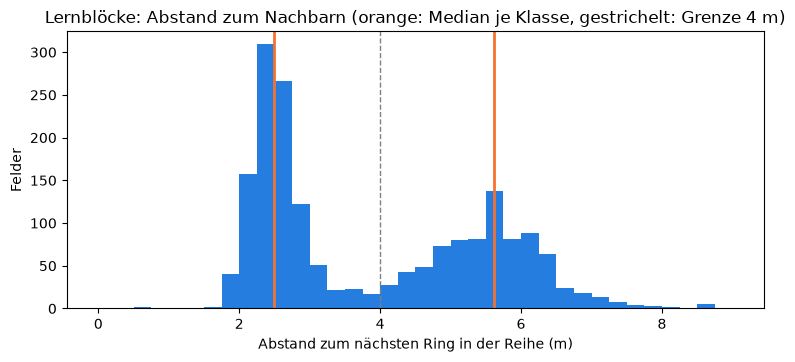

Median eng: 2.50 m | Median weit: 5.61 m


In [9]:
# Histogramm der Abstände in den Lernblöcken, mit der Grenze und den beiden Medianen
breite_eng = float(messbar[messbar.klasse == "eng"].abstand_m.median())      # typischer Abstand enger Reihen
breite_weit = float(messbar[messbar.klasse == "weit"].abstand_m.median())    # typischer Abstand weiter Reihen

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(messbar.abstand_m, bins=np.arange(0, 9.25, 0.25), color="#257de0")   # Klassen von 25 cm
ax.axvline(ENG_M, color="grey", linestyle="--", linewidth=1)                 # Grenze zwischen eng und weit
ax.axvline(breite_eng, color="#f47230", linewidth=2)                         # Median eng
ax.axvline(breite_weit, color="#f47230", linewidth=2)                        # Median weit
ax.set_xlabel("Abstand zum nächsten Ring in der Reihe (m)")
ax.set_ylabel("Felder")
ax.set_title("Lernblöcke: Abstand zum Nachbarn (orange: Median je Klasse, gestrichelt: Grenze 4 m)")
fig.savefig(ABB / "03_abstaende.png", dpi=130, bbox_inches="tight")
plt.show()
print(f"Median eng: {breite_eng:.2f} m | Median weit: {breite_weit:.2f} m")

**Was die Abbildung zeigt.** Zwei Berge: links die Felder, bei denen die Autos nebeneinander stehen, rechts jene, bei denen sie hintereinander stehen. Die gestrichelte Linie trennt die beiden Klassen. Die orangen Linien sind die typischen Abstände, die wir als Breite eines Platzes verwenden.

## 3. Vom Abstand zur Platzfläche

**Schritt 1: Breite × Tiefe.** Ein Platz nimmt entlang der Reihe den typischen Abstand ein und quer dazu die Normtiefe.

| Klasse | Breite entlang der Reihe | Tiefe quer zur Reihe |
| --- | --- | --- |
| `eng` (quer oder schräg) | gemessener Median | 5,00 m |
| `weit` (längs) | gemessener Median | 1,90 m |

Die Kästchen im Lösungsblatt werden mit **denselben** Massen gezeichnet (Notebook 04). So passt die Fläche eines Feldes im Lösungsblatt genau zu der Fläche, durch die später geteilt wird (`01b`, 8.1 K4).

In [10]:
platzmasse = {
    "eng": {"breite_m": round(breite_eng, 2), "tiefe_m": TIEFE_ENG_M, "flaeche_m2": round(breite_eng * TIEFE_ENG_M, 2)},
    "weit": {"breite_m": round(breite_weit, 2), "tiefe_m": TIEFE_WEIT_M, "flaeche_m2": round(breite_weit * TIEFE_WEIT_M, 2)},
    "ENG_M": ENG_M, "EINZELN_M": EINZELN_M,
    "TIEFE_GRENZE_M": round((TIEFE_ENG_M + TIEFE_WEIT_M) / 2, 2),   # Mitte zwischen den beiden Tiefen: 3,45 m (für Notebook 09)
    "herkunft": "Breite: Median des Abstands zum nächsten Ring der Reihe in den Lernblöcken; Tiefe: Norm (01b, Abschnitt 1)",
}
(VERARB / "platzmasse.json").write_text(json.dumps(platzmasse, indent=2, ensure_ascii=False), encoding="utf-8")
pd.DataFrame({klasse: platzmasse[klasse] for klasse in ["eng", "weit"]}).T

,breite_m,tiefe_m,flaeche_m2
eng,2.50,5.0,12.48
weit,5.61,1.9,10.66


**Schritt 2: Vergleich mit der Norm.** Die Norm dient als Kontrolle (`01b`, Abschnitt 1): Querfelder sind dort 2,50 bis 2,80 m breit, Längsfelder 5,00 bis 6,50 m lang.

In [11]:
print(f"eng:  gemessen {breite_eng:.2f} m | Norm 2,50 bis 2,80 m (quer) | gemessen ÷ 2,50 = {breite_eng / 2.50:.2f}")
print(f"weit: gemessen {breite_weit:.2f} m | Norm 5,00 bis 6,50 m (längs)")

eng:  gemessen 2.50 m | Norm 2,50 bis 2,80 m (quer) | gemessen ÷ 2,50 = 1.00
weit: gemessen 5.61 m | Norm 5,00 bis 6,50 m (längs)


## Was wir gesehen haben

- Die Ringe bilden zwei klar getrennte Gruppen: enge Reihen und weite Reihen. Die Grenze von 4 m trennt sie.
- Die Reihe eines Rings ist die Linie mit den meisten Ringen, nicht einfach der nächste Ring. An der DAV geprüft (Abschnitt 1, Schritt 5).
- Die Platzfläche je Klasse steht in der Tabelle von Abschnitt 3 und in `platzmasse.json`.
- Der Vergleich mit der Norm zeigt, ob die Zürcher Felder enger stehen als die Norm vorsieht.

## Wie es weitergeht

Notebook 04 zeichnet um jeden Ring ein Kästchen mit genau diesen Massen und prüft auf dem Luftbild, ob die Kästchen richtig liegen.